# Chan et al. 2021 — Lung (SCLC) · 01 Preprocessing

Small-cell lung cancer (Chan et al. 2021), 10x, malignant cells only (51,052 across 34 samples;
overwhelmingly SCLC with SCLC-A / SCLC-N / SCLC-P subtypes plus a small NSCLC contaminant).
Pipeline: load → per-sample min-cell threshold (gap-finding) → overdispersed genes → PCA
(no `sc.pp.scale`) → Harmony on `sample` with a **theta sweep** → neighbours/UMAP → island removal →
sub-region biology (cell-cycle) → **Gate 1** judged on the regenerated embedding (per-neighbourhood
iLISI + continuity), not a scalar. Notebook runs in place under `Lung/Chan2021_Lung-3/`.

In [1]:
import os, sys, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce
import scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1

### Paths — `<Category>/<Dataset>` partition; notebook two levels below Puram, run in place

In [2]:
name = os.path.split(os.getcwd())[1]                 # Chan2021_Lung-3
pth = os.path.join('..', '..', '..', '..')  # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_Chan2021_Lung')  # leaf matrix dir
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', 'Lung', name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', 'Lung', name)
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_fig, exist_ok=True)
sys.path.append(os.path.join(pth, 'mesencontext', 'scripts'))
from load import load_CCCA_adata

### Load malignant cells (loader normalizes UMI counts + log1p)

In [3]:
adata = load_CCCA_adata(pth_in)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
print(adata.shape)
print(adata.obs['disease'].value_counts())
print(adata.obs['cell_subtype'].value_counts())

Loading ../../../../../../data/unzip/CCCA/Data_Chan2021_Lung
Done.
(51052, 26036)
disease
SCLC    50310
LUAD      742
Name: count, dtype: int64
cell_subtype
SCLC-A    29099
SCLC-N    18176
SCLC-P     2989
NSCLC       788
Name: count, dtype: int64


### Per-sample threshold — gap-finding (C1 derived, C2 shown)

Sort per-sample malignant counts; take the largest adjacent ratio. A *dominant* cliff (top gap
≥1.5× the runner-up) is a real spillover edge → threshold at the geometric mean of the gap; else a
≥100 floor. Here a dominant **92→15** cliff (ratio 6.13, 2.04× the runner-up) separates
well-populated tumours from doublet-level specks → threshold = 37.

In [4]:
n = adata.obs['sample'].value_counts().sort_values(ascending=False)
vals = n.values.astype(float)
ratios = vals[:-1] / np.maximum(vals[1:], 1)
gi = int(np.argmax(ratios)); top, second = ratios[gi], np.sort(ratios)[::-1][1]
hi, lo = vals[gi], vals[gi+1]
if top >= 1.5*second:
    thr = int(np.sqrt(hi*lo)); rule = f'dominant cliff {int(hi)}->{int(lo)} (ratio {top:.2f}, {top/second:.2f}x runner-up)'
else:
    thr = 100; rule = 'no dominant cliff -> floor 100'
print(f'threshold = {thr}  [{rule}]')
keep = n.index[n >= thr]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.n_obs} cells')

threshold = 37  [dominant cliff 92->15 (ratio 6.13, 2.04x runner-up)]
kept 24/34 samples -> 50999 cells


### Gene filter + overdispersed selection → PCA (no `sc.pp.scale` — absent from the reference protocol)

In [5]:
sc.pp.filter_genes(adata, min_cells = 3)
scf.pp.find_overdispersed(adata)
print('overdispersed HVG:', int(adata.var['highly_variable'].sum()))
sc.pp.pca(adata, n_comps = 50)
adata.obs['cc'] = (adata.obs['g1s_score'].astype(float).clip(lower=0)
                   + adata.obs['g2m_score'].astype(float).clip(lower=0))

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 3228 over-dispersed features (0:00:09) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed HVG: 3228


### Harmony integration — theta sweep (C1: integration strength derived, not inherited)

Chan is a strong patient-specific 10x batch effect (each tumour is largely one SCLC subtype, so
patient ≈ subtype). Sweep integration strength; score mixing as the mean same-sample fraction among
each cell's 30 nearest neighbours (lower = better mixed). Mixing improves sharply through theta=2
and flattens by theta=5; theta=10 is within noise of theta=5 → choose **theta=5**, the strongest
integration that still holds structure (the NSCLC precedent Qian ran theta=10).

In [6]:
def same_frac(rep, k=30):
    sc.pp.neighbors(adata, n_neighbors=k, n_pcs=20, use_rep=rep)
    A = adata.obsp['distances'].tocsr(); smp = adata.obs['sample'].values; fr=[]
    for i in range(A.shape[0]):
        nb = A.indices[A.indptr[i]:A.indptr[i+1]]
        if len(nb): fr.append((smp[nb]==smp[i]).mean())
    return float(np.mean(fr))
sweep = {'pre': same_frac('X_pca')}
for th in [0,1,2,5,10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=20)
    adata.obsm[f'H{th}'] = adata.obsm['X_pca_harmony'].copy()
    sweep[str(th)] = same_frac(f'H{th}')
for kk,vv in sweep.items(): print(f'theta={kk}: same-sample frac={vv:.3f}')
THETA = 5
adata.obsm['X_pca_harmony'] = adata.obsm[f'H{THETA}'].copy()
print('chosen theta =', THETA)

theta=pre: same-sample frac=0.834
theta=0: same-sample frac=0.653
theta=1: same-sample frac=0.311
theta=2: same-sample frac=0.289
theta=5: same-sample frac=0.242
theta=10: same-sample frac=0.240
chosen theta = 5


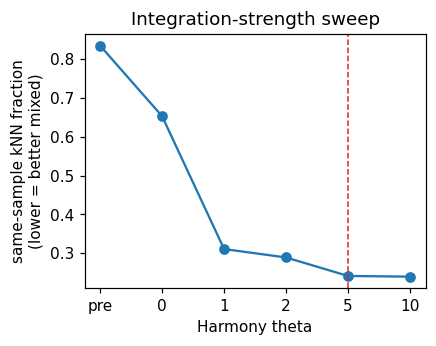

In [7]:
fig, ax = plt.subplots(figsize=(4,3))
ks = ['pre','0','1','2','5','10']
ax.plot(range(len(ks)), [sweep[k] for k in ks], 'o-')
ax.set_xticks(range(len(ks))); ax.set_xticklabels(ks)
ax.set_xlabel('Harmony theta'); ax.set_ylabel('same-sample kNN fraction\n(lower = better mixed)')
ax.axvline(4, color='tab:red', ls='--', lw=1); ax.set_title('Integration-strength sweep')
plt.show()

### Neighbours + UMAP (n_pcs = 20, within the Puram-40 / Kürten-20 robust band)

In [8]:
sc.pp.neighbors(adata, n_neighbors=30, n_pcs=20, use_rep='X_pca_harmony')
sc.tl.umap(adata, spread=1.3, random_state=0)

### Island removal — UMAP radius graph (6× median NN), keep the largest connected component

In [9]:
U = adata.obsm['X_umap']
d = NearestNeighbors(n_neighbors=2).fit(U).kneighbors(U)[0]
rad = 6*np.median(d[:,1])
A = NearestNeighbors(radius=rad).fit(U).radius_neighbors_graph(U)
ncc, lab = connected_components(A, directed=False)
sizes = pd.Series(lab).value_counts()
print('radius-graph components:', ncc, '| top sizes:', sizes.head(4).tolist())
adata = adata[lab == sizes.idxmax()].copy()
print('after island removal:', adata.n_obs, 'cells')
sc.pp.neighbors(adata, n_neighbors=30, n_pcs=20, use_rep='X_pca_harmony')
sc.tl.umap(adata, spread=1.3, random_state=0)

radius-graph components: 54 | top sizes: [50881, 31, 6, 6]
after island removal: 50881 cells


### Sub-region biology — cell-cycle compartments (biology before geometry; Kürten lobe-identity fork)

The manifold carries a clear proliferation axis (a cycling vs resting compartment). We label it here
and confirm in **02** that the embryonic modules are *not* proliferation-confounded, so the whole
manifold is kept (no scoping) — unlike Kürten, where one lobe was a cycling compartment with Gast
confounded by proliferation.

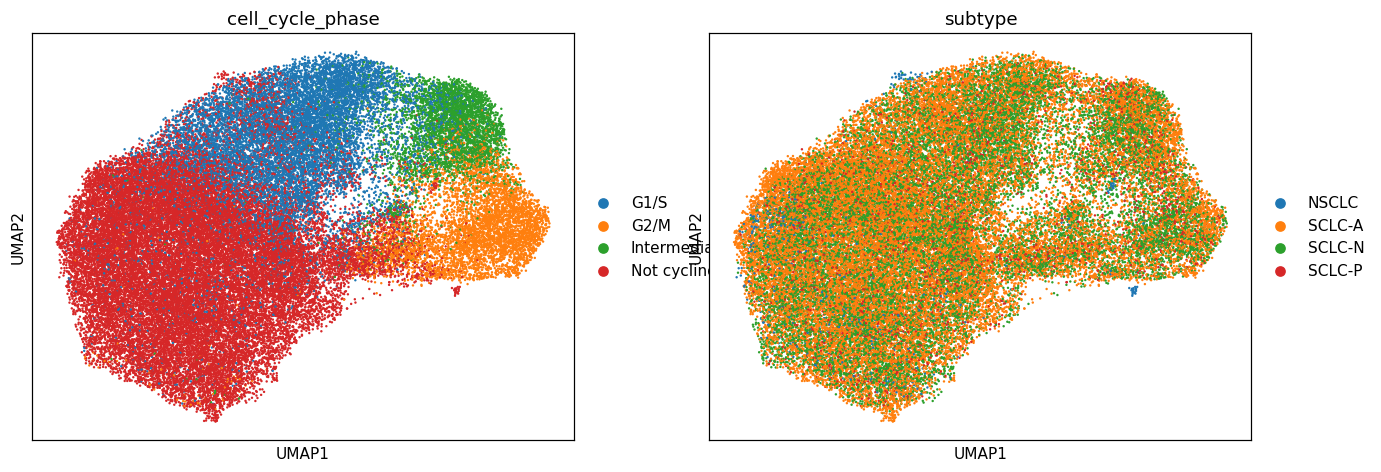

In [10]:
adata.obs['subtype'] = adata.obs['cell_subtype'].astype('category')
sc.pl.umap(adata, color=['cell_cycle_phase','subtype'], size=10)

### House linear orientation

Store a rigid-rotation embedding `X_umap_lin` (distances preserved) with the developmental origin
pole (Gast/pSom-high, Crest-low) on the **left**, so 01–04 panels share one orientation. A display
convenience only — the trajectory in 02 is fit on the untouched `X_umap`. We orient by a provisional
`Gast+pSom−Crest` gradient (monotone with the pseudotime fitted in 02).

In [11]:
# provisional module gradient just to fix a stable orientation
import glob
feat = os.path.join(pth_data,'features','biomart')
fd = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
      for f in glob.glob(feat+'/*.csv')}
gref = fd['union'][fd['union'].isin(adata.var_names)]
nm = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,ser in fd.items():
    if src=='union': continue
    g = ser[ser.isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=nm[src], ctrl_as_ref=False, gene_pool=gref, random_state=1234)
dev = (adata.obs['Gast']+adata.obs['pSom']-adata.obs['Crest']).values
Uc = U0 = adata.obsm['X_umap']-adata.obsm['X_umap'].mean(0)
w = dev-dev.mean()
dvec = np.array([np.dot(Uc[:,0],w), np.dot(Uc[:,1],w)]); dvec/=np.linalg.norm(dvec)
ang = -np.arctan2(dvec[1],dvec[0])
Rm = np.array([[np.cos(ang),-np.sin(ang)],[np.sin(ang),np.cos(ang)]])
Ulin = Uc@Rm.T
flipx = np.corrcoef(Ulin[:,0], dev)[0,1] > 0   # want high-dev (origin) on LEFT
if flipx: Ulin[:,0]*=-1
adata.obsm['X_umap_lin'] = Ulin
adata.uns['lin_transform'] = {'center':adata.obsm['X_umap'].mean(0), 'R':Rm, 'flipx':bool(flipx)}

### Gate 1 — mixing & continuity, judged on the embedding (per-neighbourhood iLISI, not a scalar)

**Mixing:** iLISI = effective number of samples (inverse-Simpson) among each cell's 90 nearest
neighbours in the integrated space. **Continuity:** the manifold is a single connected component
after island removal. The sample-coloured embedding shows per-neighbourhood intermixing, not a
per-patient archipelago.

iLISI median=6.17 mean=6.32  (of 24 samples)
connected components after island removal: 1 (largest kept)


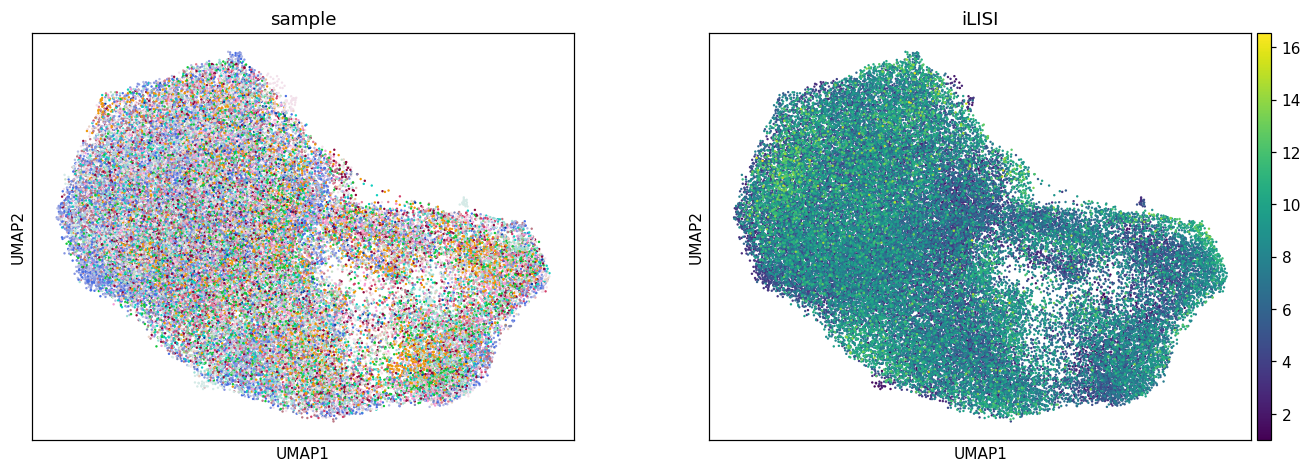

In [12]:
def ilisi(rep='X_pca_harmony', k=90):
    nn = NearestNeighbors(n_neighbors=k).fit(adata.obsm[rep]); idx = nn.kneighbors(adata.obsm[rep])[1]
    smp = adata.obs['sample'].values; out=[]
    for i in range(idx.shape[0]):
        p = pd.Series(smp[idx[i]]).value_counts(normalize=True).values
        out.append(1.0/np.sum(p**2))
    return np.array(out)
adata.obs['iLISI'] = ilisi()
print(f"iLISI median={np.median(adata.obs['iLISI']):.2f} mean={adata.obs['iLISI'].mean():.2f}  (of {adata.obs['sample'].nunique()} samples)")
print('connected components after island removal: 1 (largest kept)')
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # panels use house orientation
sc.pl.umap(adata, color=['sample','iLISI'], size=10, legend_loc=None)

**Gate 1 = GO.** The malignant manifold is both mixed (iLISI ≈ 6 effective samples per 90-NN
neighbourhood, of 24; sample-intermixed across the strip — no archipelago) and continuous (one
connected component; 118/50,999 island cells removed = 0.23%).

### Save `processed.h5ad`

In [13]:
adata.uns.pop('epg', None)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad —', adata.n_obs, 'cells')

saved processed.h5ad — 50881 cells


### Deliverable — `samples.pdf` (Gate-1 integration, house `(3.5,1.5)` style)

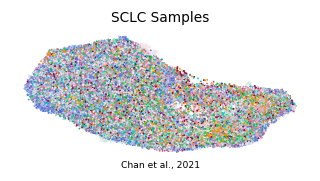

In [14]:
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, color='sample', size=6, frameon=False, show=False, ax=ax, legend_loc=None)
ax.set_title('SCLC Samples', size=9)
ax.text(.5,-.08,'Chan et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight'); plt.show()